# Séance 1 - Bonus : Première régularisation d'un réseau de neurones

Pour poursuivre le travail du TP, on se propose d'explorer une première manière de régulariser un réseau de neurones. Nous avons vu que nous pouvions atteindre de bonne performances, mais que cela entraînait fréquemment un sur-apprentissage.
Une des premières manières de régulariser que l'on apprend en Machine Learning est de pénaliser une régression linéaire : c'est la régression Ridge. Le principe est de modifier la fonction de perte pour contraindre les poids appris à être *petit*. Il est possible de le faire couche par couche dans un réseau de neurones. Essayons !

Commençons par importer et traiter les données.

In [1]:
import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; sns.set(style='whitegrid')

import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

(X_train_full, y_train_full), (X_test, y_test) = (keras.datasets.mnist.load_data())
X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full, train_size=0.8)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train.astype(np.float32).reshape(-1, 28 * 28)).reshape(-1, 28, 28)
X_valid = scaler.transform(X_valid.astype(np.float32).reshape(-1, 28 * 28)).reshape(-1, 28, 28)
X_test = scaler.transform(X_test.astype(np.float32).reshape(-1, 28 * 28)).reshape(-1, 28, 28)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## Pénalisation $L_2$

La pénalisation à laquelle on s'intéresse ici est la pénalisation $L_2$. Si l'on considère un problème d'optimisation d'une fonction de perte $\mathcal{L}$

$$w^* = \arg\min_{w\in\mathbb{R}^d} \mathcal{L}(w)$$

Alors sa version pénalisée est la suivante avec $\lambda > 0$ :

$$w^* = \arg\min_{w\in\mathbb{R}^d} \mathcal{L}(w) + \lambda\|w\|^2$$

Ce n'est plus exactement le même objectif puisqu'on force ici le vecteur solution $w^*$ a prendre de plus petite valeurs. Nous pouvons faire cela couche par couche.

**Consigne** : Définir un modèle en ajoutant une pénalisation [$L_2$](https://keras.io/api/layers/regularizers/#l2-class) aux couches [`Dense`](https://keras.io/api/layers/core_layers/dense/).

In [2]:
model = keras.models.Sequential([
    keras.layers.Input(shape=[28, 28]),
    keras.layers.Flatten(),
    keras.layers.Dense(256, activation="relu", kernel_regularizer='l2'),
    keras.layers.Dense(128, activation="relu", kernel_regularizer='l2'),
    keras.layers.Dense(10, activation="softmax", kernel_regularizer='l2')
])

**Consigne** : Lancer sur quelques époques le modèle pour valider qu'il fonctionne correctement.

In [3]:
model.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.SGD(learning_rate=1e-3), metrics=["accuracy"])

epochs = 5
batch_size = 128

history = model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_data=(X_valid, y_valid))

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.3212 - loss: 7.7704 - val_accuracy: 0.4947 - val_loss: 7.3754
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6016 - loss: 7.0509 - val_accuracy: 0.6750 - val_loss: 6.8568
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.7296 - loss: 6.6253 - val_accuracy: 0.7583 - val_loss: 6.5265
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.7899 - loss: 6.3416 - val_accuracy: 0.8023 - val_loss: 6.2987
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8249 - loss: 6.1362 - val_accuracy: 0.8266 - val_loss: 6.1270


In [4]:
display(pd.DataFrame(history.history))

,accuracy,loss,val_accuracy,val_loss
0,0.321208,7.770435,0.494667,7.375422
1,0.601625,7.050935,0.675000,6.856802
2,0.729563,6.625278,0.758333,6.526535
3,0.789937,6.341622,0.802333,6.298657
4,0.824896,6.136237,0.826583,6.127047


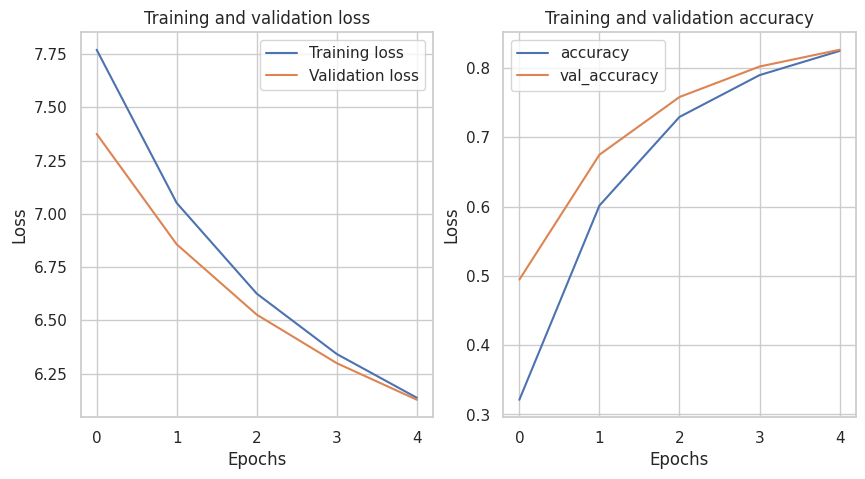

In [5]:
def plot_learning_curves(history):
  fig,axs = plt.subplots(1, 2, figsize=(10, 5))
  axs[0].plot(history.history['loss'], label='Training loss')
  axs[0].plot(history.history['val_loss'], label='Validation loss')
  axs[0].set_xlabel('Epochs')
  axs[0].set_ylabel('Loss')
  axs[0].set_title('Training and validation loss')
  axs[0].legend()

  axs[1].plot(history.history['accuracy'], label='accuracy')
  axs[1].plot(history.history['val_accuracy'], label='val_accuracy')
  axs[1].set_xlabel('Epochs')
  axs[1].set_ylabel('Loss')
  axs[1].set_title('Training and validation accuracy')
  axs[1].legend()

  plt.show()

plot_learning_curves(history)

In [7]:
predict = model.predict(X_test, batch_size=batch_size, verbose="auto", steps=None, callbacks=None)
predict

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


array([[1.0609705e-03, 1.2227847e-03, 1.9860337e-03, ..., 9.4220388e-01,
        2.4082537e-03, 3.2099348e-02],
       [1.3433347e-03, 2.1607189e-03, 8.1906873e-01, ..., 3.0773145e-04,
        3.9222684e-02, 1.5373438e-04],
       [6.7275353e-03, 8.5489762e-01, 1.9479008e-02, ..., 8.0787418e-03,
        2.5544113e-02, 1.2943466e-02],
       ...,
       [2.1218315e-03, 1.5921103e-02, 3.9240392e-03, ..., 4.9881212e-02,
        5.6791764e-02, 3.1700590e-01],
       [1.7079192e-03, 3.3412281e-02, 6.6654678e-03, ..., 2.8981261e-03,
        5.6797564e-02, 2.6212158e-02],
       [2.3095685e-03, 9.9006720e-06, 4.9685929e-03, ..., 4.5997353e-05,
        6.1517334e-05, 4.0274397e-05]], shape=(10000, 10), dtype=float32)

Sum of the first image matrix : 0.99999994
Predicted class for the first image : 7


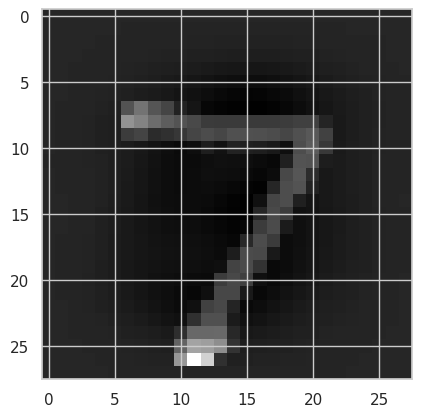

In [8]:
print("Sum of the first image matrix :",  predict[0].sum())

print("Predicted class for the first image :", np.argmax(predict[0]))

plt.imshow(X_test[0], cmap='gray')
plt.show()

De la même manière que l'on souhaitais observer l'impact du learning rate sur l'entraînement, on souhaite mesurer l'apport de la régularisation au modèle.

## Mesure de l'impact de la régularisation

**Consigne** : Définir une fonction `get_model` qui prend en paramètre :
* *lambda_l2* : float correspondant à la magnitude de la pénalisation $L_2$
* *learning_rate* : float par défaut à $0.001$ correspond au learning rate de l'optimizer

La fonction renvoie le modèle compilé.

In [11]:
def get_model(lambda_l2=0, learning_rate=0.001):
  model = keras.models.Sequential([
    keras.layers.Input(shape=[28, 28]),
    keras.layers.Flatten(),
    keras.layers.Dense(256, activation="relu", kernel_regularizer=keras.regularizers.L2(lambda_l2)),
    keras.layers.Dense(128, activation="relu", kernel_regularizer=keras.regularizers.L2(lambda_l2)),
    keras.layers.Dense(10, activation="softmax", kernel_regularizer=keras.regularizers.L2(lambda_l2))
  ])
  model.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.SGD(learning_rate=learning_rate), metrics=["accuracy"])
  return model

**Consigne** : En s'inspirant du travail réalisé pour le learning rate, comparer différente valeur de régularisation. Commenter.

In [12]:
n_epochs = 5
batch_size = 32
lambda_l2_list = [10**(-power) for power in range(1, 4)]

results = []
for lambda_l2 in lambda_l2_list:
  print("lambda_l2: %f - époques: %d" % (lambda_l2, n_epochs))
  model = get_model(lambda_l2,learning_rate=0.001)
  history = model.fit(X_train, y_train, epochs=n_epochs, batch_size=batch_size, validation_data=(X_valid, y_valid))
  result = {"lambda_l2": lambda_l2, "n_epochs": n_epochs, "history": pd.DataFrame(history.history)}
  results.append(result)

lambda_l2: 0.100000 - époques: 5
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.6053 - loss: 44.8889 - val_accuracy: 0.7707 - val_loss: 33.0426
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8068 - loss: 25.2781 - val_accuracy: 0.8173 - val_loss: 18.9937
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.8279 - loss: 14.7724 - val_accuracy: 0.8247 - val_loss: 11.3620
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.8283 - loss: 9.0513 - val_accuracy: 0.8202 - val_loss: 7.1934
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.8249 - loss: 5.9201 - val_accuracy: 0.8161 - val_loss: 4.9053
lambda_l2: 0.010000 - époques: 5
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.6450 - loss: 6.9187 - val_accuracy: 0.8088 - val_loss: 6.2610
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8502 - loss: 5.9334 - val_accuracy: 0.8655 - val_loss: 5.7138
Epoch 3/5
1500/1500

On voit que plus on reduit le $\lambda_2$ plus on accelère la convergence de la loss mais les coûts de calcul augmentent.